In [13]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import os
import torch
from torchvision import transforms
import onnxruntime 
import time
import openvino as ov
# import ipywidgets as widgets
import sys


In [14]:
sys.path.insert(0,"../")

def convert_to_onnx(model,model_path,device):

    onnx_path=model_path.split('.')[0]+'.onnx'
    input_clothes = torch.ones(1,3,256,192).to(device)
    input_person = torch.ones(1,3,256,192).to(device)



    #转onnx
    torch.onnx.export(model,(input_person,input_clothes),onnx_path,opset_version=16,input_names=['input_person','input_clothes'], 
            output_names=['output'])
    print("onnx_path保存路径:\n",onnx_path)
    
def onnx_output(input_person_np,input_clothes_np,onnx_path):
        #onnx推理模型
        ort_session = onnxruntime.InferenceSession(onnx_path)
        start_time = time.time()
        ort_inputs = {'input_clothes': input_clothes_np,'input_person':input_person_np}
        # ort_inputs = {'input_clothes': source_image_np,'input_person':ref_image_np} 
        ort_output = ort_session.run(['output'], ort_inputs)[0] 
        end_time = time.time()
        # 计算并打印运行时间
        execution_time = end_time - start_time
        print(f"Execution time: {execution_time:.4f} seconds")  # 
        #对onnx输出处理
        value_range = (np.min(ort_output),np.max(ort_output)) #此处进行归一化
        onnx_output_result = ((ort_output - value_range[0]) / (value_range[1] - value_range[0])) * 255
        onnx_output_result = onnx_output_result.astype(np.uint8)  # 将数据转换为 uint8

        onnx_output_result = np.transpose(onnx_output_result, (2, 3, 1, 0))


        onnx_output_result = np.squeeze(onnx_output_result)
        
        return onnx_output_result

In [15]:

def post_process(input_person,input_clothes):
    #由于没有对数据预处理，当直接输入图片时，导致无法得到理想结果，因此对数据进行预处理，预处理的方法需要自己的源码中所使用的方法。
    #输入预处理
    load_width = 192

    transform = transforms.Compose([
                transforms.ToTensor(),
                transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
            ])
    input_clothes = transforms.Resize(load_width, interpolation=2)(input_clothes)
    input_person = transforms.Resize(load_width, interpolation=2)(input_person)
    input_clothes = transform(input_clothes).unsqueeze(0)  #torch.Size([1,3, 256, 192])
    input_person = transform(input_person).unsqueeze(0)#torch.Size([1,3, 256, 192])

    input_clothes_np = np.array(input_clothes).astype(np.float32)
    input_person_np = np.array(input_person).astype(np.float32)
    return input_person,input_clothes,input_person_np,input_clothes_np

In [16]:
# 原模型


model_path='/mnt/bb/yc/virtual-tryon-ds/checkpoint/checkpoint_bypy/pf_b_2l2e-05_0.5_/pf_b_2l2e-05_0.5__data.pt'
# model_path='/mnt/bb/yc/virtual-tryon-ds/checkpoint/checkpoint_bypy/pf_b_2l2e-05m_35/pf_b_2l2e-05m_35_data.pt'
# model_path='/mnt/bb/yc/virtual-tryon-ds/checkpoint/checkpoint_bypy/pf_b_2l2e-05m_63/pf_b_2l2e-05m_63_data.pt'
onnx_path=model_path.split('.')[0]+'.onnx'
device = "cpu"
input_clothes_path='/mnt/bb/yc/virtual-tryon-ds/data/VITON/VITON/VITON_test/clothes/000010_1.jpg'
input_person_path="/mnt/bb/yc/virtual-tryon-ds/data/VITON/VITON/VITON_test/test_img/000228_0.jpg"
input_clothes = Image.open(input_clothes_path).convert('RGB')
input_person = Image.open(input_person_path).convert('RGB')
plt_clothes = input_clothes #拷贝一份，用于之后绘制图像
plt_person = input_person

model = torch.load(model_path,map_location='cpu')
model = model.to(device)
input_person,input_clothes,input_person_np,input_clothes_np = post_process(input_person,input_clothes)

# onnx模型导出
convert_to_onnx(model,model_path,'cpu')
# onnx推理
onnx_output_result = onnx_output(input_person_np,input_clothes_np,onnx_path)


/mnt/bb/yc/virtual-tryon-ds/deploy/../models/never_parse_ds_studentmodel.py:205: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if return_all:
/mnt/zz/anaconda3/envs/torch2.0/lib/python3.8/site-packages/torch/functional.py:507: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3549.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
/mnt/zz/anaconda3/envs/torch2.0/lib/python3.8/site-packages/torch/nn/functional.py:4316: UserWarning: Default grid_sample and affine_grid behavior has changed to align_corners=False since 1.3.0. Please specify align_corners=True if the old behavior is desired. See the documentation of grid_sample for det

onnx_path保存路径:
 /mnt/bb/yc/virtual-tryon-ds/checkpoint/checkpoint_bypy/pf_b_2l2e-05_0.onnx
Execution time: 0.8493 seconds


(256, 192, 3)


(-0.5, 191.5, 255.5, -0.5)

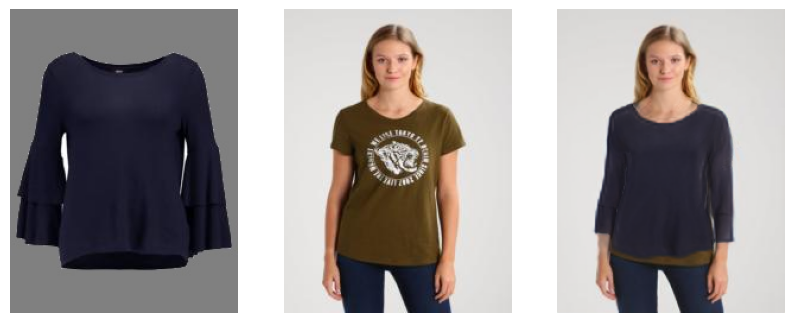

In [17]:
# onnx可视化
fig, axes = plt.subplots(1, 3, figsize=(10, 5))
# 转换为numpy对象
plt_clothes_np = np.array(plt_clothes)
plt_person_np = np.array(plt_person)

plt_clothes_np = np.array(plt_clothes_np)
plt_person_np = np.array(plt_person_np)
print(plt_person_np.shape)

# 在第一个子图上显示衣服图像
axes[0].imshow(plt_clothes_np)
axes[0].axis('off')

# 在第二个子图上显示人物图像
axes[1].imshow(plt_person_np)
axes[1].axis('off')

axes[2].imshow(onnx_output_result)
axes[2].axis('off')
